In [1]:
import matplotlib.pyplot as plt        # plotting
import numpy as np                     # numerical arrays and np.pi
from qiskit import QuantumCircuit                 # the object we build circuits with
from qiskit.visualization import plot_histogram   # bar chart of measurement counts
import math
from math import gcd                   # greatest common divisor
from numpy.random import randint       # random integers
import pandas as pd                    # tables (DataFrame) for printing results
from fractions import Fraction         # exact rational numbers; .limit_denominator() = continued fractions
print("Imports Successful")


Imports Successful


In [2]:
# Define the number to be factored (N)
N = 15

# Define the number of qubits needed to store the number N
n = math.ceil(math.log(N, 2))

# Define the number of qubits needed to store the value of a
m = 2 * n
a = 3

In [3]:
print(N,n,m,a)

15 4 8 3


Could not find period, check a < N and have no common factors.


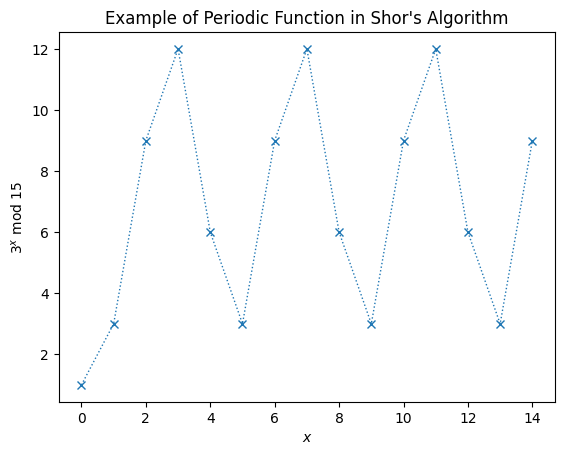

In [4]:
# Calculate the plotting data
xvals = np.arange(N)                         # NumPy array 0, 1, ..., N-1
yvals = [np.mod(a**x, N) for x in xvals]     # list comprehension: a^x mod N for every x

# Use matplotlib to display it nicely
fig, ax = plt.subplots()                     # one figure with one set of axes
ax.plot(xvals, yvals, linewidth=1, linestyle='dotted', marker='x')
ax.set(xlabel='$x$', ylabel=f'${a}^x$ mod ${N}$',          # f-string: {a} and {N} are replaced by their values
       title="Example of Periodic Function in Shor's Algorithm")
try: # plot r on the graph
    r = yvals[1:].index(1) + 1               # first x > 0 with a^x mod N == 1, i.e. the period r
    plt.annotate('', xy=(0,1), xytext=(r,1),
                 arrowprops=dict(arrowstyle='<->'))
    plt.annotate(f'$r={r}$', xy=(r/3,1.5))
except ValueError:                           # list.index() raises ValueError if 1 never appears
    print('Could not find period, check a < N and have no common factors.')


## Implementation of period finding
In this example we will solve the period finding problem for $a=7$ and $N=15$
. We provide the circuits for 
 where:
$U|y\rangle = |ay\bmod 15\rangle$ without explanation. To create $U^x$ , we will simply repeat the circuit $x$ 
 times. In the next section we will discuss a general method for creating these circuits efficiently. The function c_amod15 returns the controlled-U gate for a, repeated power times.

In [5]:
# Specify variables
N_COUNT = 8  # number of counting qubits
a = 7

In [6]:
def c_amod15(a, power):
    """Controlled multiplication by a mod 15"""
    if a not in [2,4,7,8,11,13]:
        raise ValueError("'a' must be 2,4,7,8,11 or 13")   # raise = abort with an error message
    U = QuantumCircuit(4)                 # a 4-qubit circuit (no classical bits): the work register
    # Textbook version: apply U `power` times in a row (slow for large powers; see shor.ipynb for the
    # classical shortcut). U.swap(i, j) exchanges qubits i and j, U.x(q) applies a NOT to qubit q.
    for _iteration in range(power):
        if a in [2,13]:
            U.swap(2,3)
            U.swap(1,2)
            U.swap(0,1)
        if a in [7,8]:
            U.swap(0,1)
            U.swap(1,2)
            U.swap(2,3)
        if a in [4, 11]:
            U.swap(1,3)
            U.swap(0,2)
        if a in [7,11,13]:
            for q in range(4):
                U.x(q)
    U = U.to_gate()                       # pack the circuit into a single reusable Gate object
    U.name = f"{a}^{power} mod 15"        # label shown in circuit drawings
    c_U = U.control()                     # add one control qubit -> controlled-U
    return c_U


In [7]:
def qft_dagger(n):
    """n-qubit QFTdagger the first n qubits in circ"""
    qc = QuantumCircuit(n)
    # Don't forget the Swaps!
    for qubit in range(n//2):                        # reverse the qubit order
        qc.swap(qubit, n-qubit-1)
    for j in range(n):
        for m in range(j):
            qc.cp(-np.pi/float(2**(j-m)), m, j)      # qc.cp(theta, control, target): controlled phase gate
        qc.h(j)                                      # Hadamard on qubit j
    qc.name = "QFT†"                                 # label shown in circuit drawings
    return qc


Let us look at the two building blocks before assembling them. `draw('mpl')` renders a circuit with
matplotlib. A gate has no `draw()`, so for the controlled multiplication we draw `base_gate.definition`
(the circuit of $U$ without its control); `decompose()` expands composite gates by one level.


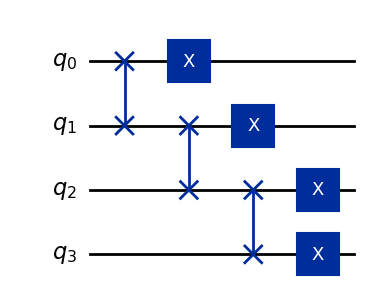

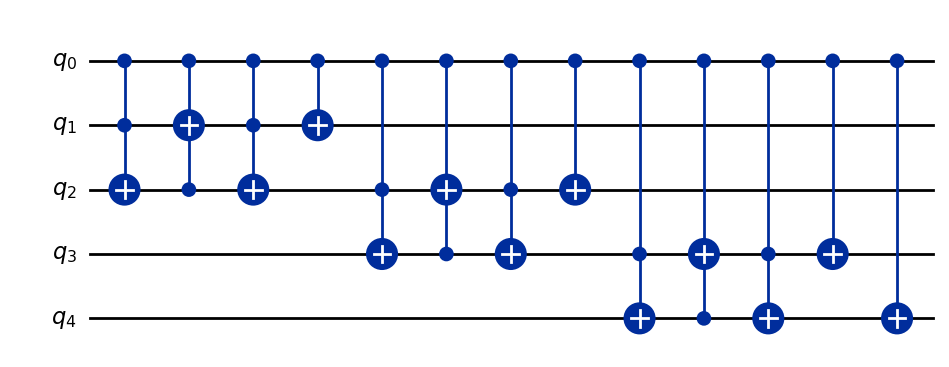

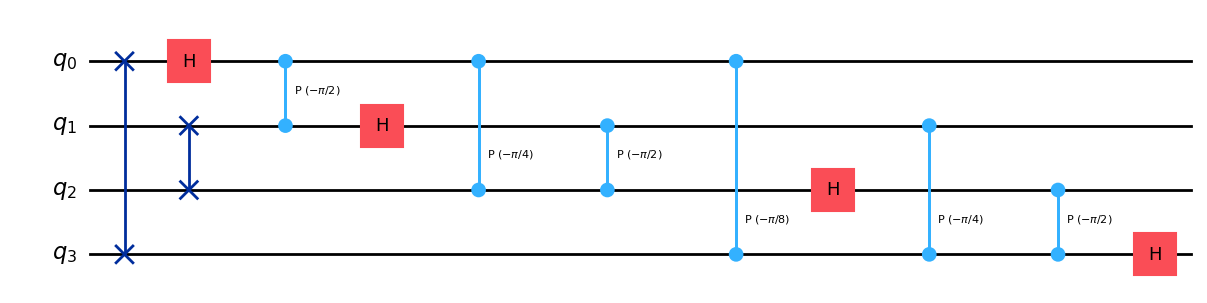

In [8]:
# U for a = 7, power = 1: multiplication by 7 mod 15 on the 4-qubit work register
display(c_amod15(7, 1).base_gate.definition.draw('mpl'))   # display(): show a figure that is not the last line

# The controlled version inside a 5-qubit circuit (qubit 0 = control), expanded one level
cU = QuantumCircuit(5)
cU.append(c_amod15(7, 1), [0, 1, 2, 3, 4])    # append(gate, qubits): control first, then the 4 work qubits
display(cU.decompose().draw('mpl'))

# The inverse QFT on 4 qubits (the last expression of a cell is displayed automatically)
qft_dagger(4).draw('mpl')


In [9]:
# Create QuantumCircuit with N_COUNT counting qubits
# plus 4 qubits for U to act on
qc = QuantumCircuit(N_COUNT + 4, N_COUNT)   # QuantumCircuit(number_of_qubits, number_of_classical_bits)

# Initialize counting qubits
# in state |+>
for q in range(N_COUNT):
    qc.h(q)                                 # Hadamard on qubit q

# And auxiliary register in state |1>
qc.x(N_COUNT)                               # NOT on the first work qubit

# Do controlled-U operations
for q in range(N_COUNT):
    # qc.append(gate, qubits): the list names the qubits the gate acts on, control first
    qc.append(c_amod15(a, 2**q),
             [q] + [i+N_COUNT for i in range(4)])

# Do inverse-QFT
qc.append(qft_dagger(N_COUNT), range(N_COUNT))

# Measure circuit
qc.measure(range(N_COUNT), range(N_COUNT))  # measure(qubits, classical_bits): qubit q -> bit q
print(f"{qc.num_qubits} qubits, {qc.num_clbits} classical bits, depth {qc.depth()}")


12 qubits, 8 classical bits, depth 11


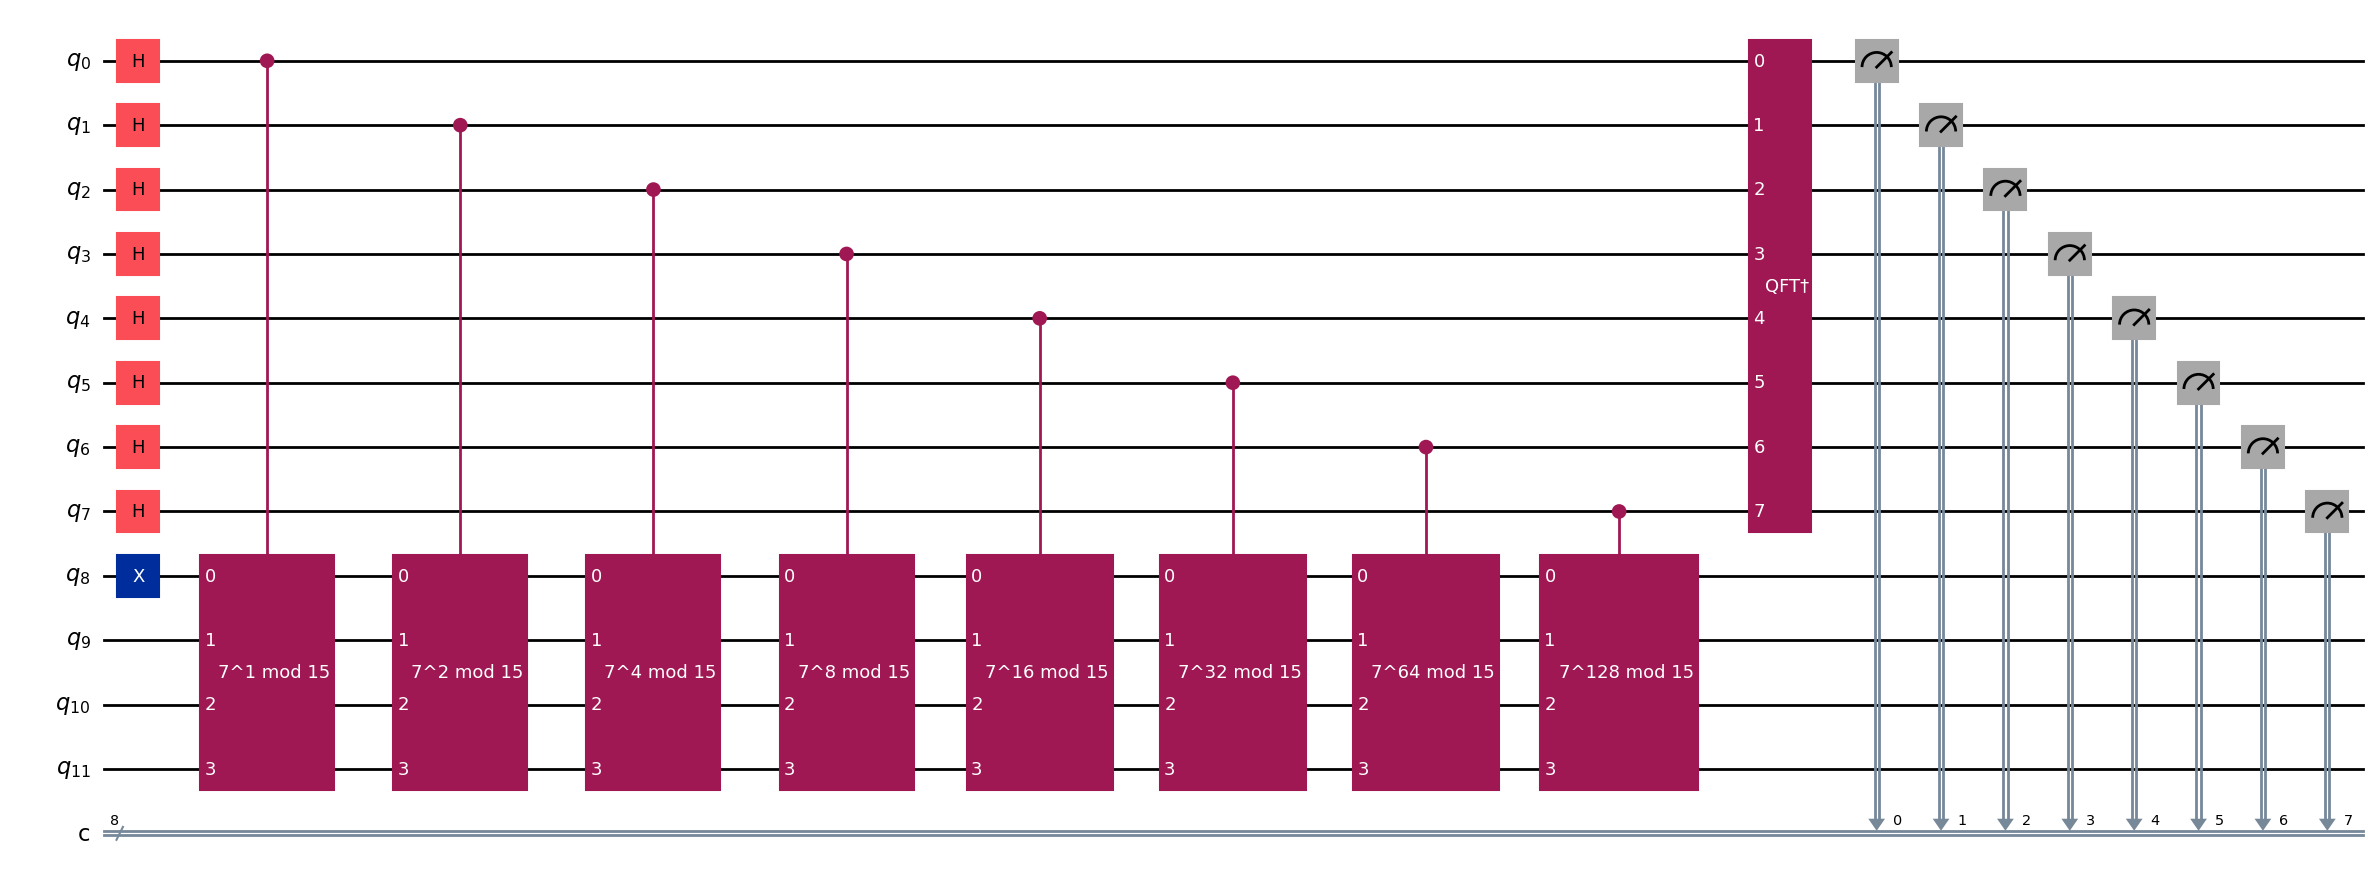

In [10]:
qc.draw('mpl',fold=-1)  # -1 means 'do not fold'

In [11]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler
from qiskit_aer import AerSimulator                                                # local simulator
from qiskit_aer.primitives import SamplerV2 as Sampler                             # (primitive interface, not used below)


In [12]:
sampler = Sampler()
# The circuit needs to be transpiled to the AerSimulator target
pass_manager = generate_preset_pass_manager(3, AerSimulator())   # optimization_level 3 = most aggressive
qc_isa_circuit = pass_manager.run(qc)                            # rewrite qc with the backend's native gates
print(f"transpiled: {qc_isa_circuit.size()} gates, depth {qc_isa_circuit.depth()}")
#isa_observable = observable.apply_layout(isa_circuit.layout)


transpiled: 3368 gates, depth 3297


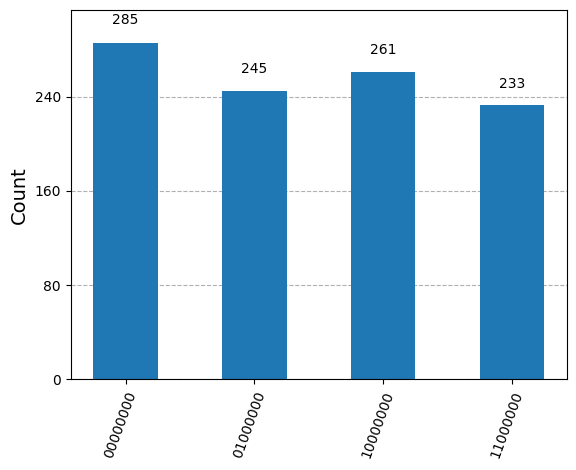

In [13]:
sim = AerSimulator()                            # local ideal simulator
results = sim.run(qc_isa_circuit).result()      # run (default 1024 shots) and wait for the result
counts = results.get_counts()                   # dict {'bitstring': how many shots gave it}
plot_histogram(counts)


In [14]:
rows, measured_phases = [], []
for output in counts:                 # iterating over a dict gives its keys: the measured bitstrings
    decimal = int(output, 2)  # Convert (base 2) string to decimal
    phase = decimal/(2**N_COUNT)  # Find corresponding eigenvalue
    measured_phases.append(phase)
    # Add these values to the rows in our table:
    rows.append([f"{output}(bin) = {decimal:>3}(dec)",     # :>3 = right-align in 3 characters
                 f"{decimal}/{2**N_COUNT} = {phase:.2f}"])   # :.2f = 2 decimal places
# Print the rows in a table
headers=["Register Output", "Phase"]
df = pd.DataFrame(rows, columns=headers)       # pandas table
print(df)


            Register Output           Phase
0  01000000(bin) =  64(dec)   64/256 = 0.25
1  00000000(bin) =   0(dec)    0/256 = 0.00
2  11000000(bin) = 192(dec)  192/256 = 0.75
3  10000000(bin) = 128(dec)  128/256 = 0.50


In [15]:
rows = []
for phase in measured_phases:
    frac = Fraction(phase).limit_denominator(15)   # continued fractions: closest s/r with r <= 15
    rows.append([phase,
                 f"{frac.numerator}/{frac.denominator}",
                 frac.denominator])
# Print as a table
headers=["Phase", "Fraction", "Guess for r"]
df = pd.DataFrame(rows, columns=headers)
print(df)


   Phase Fraction  Guess for r
0   0.25      1/4            4
1   0.00      0/1            1
2   0.75      3/4            4
3   0.50      1/2            2


We can see that two of the measured eigenvalues provided us with the correct result: $r=4$, and we can see that Shor’s algorithm has a chance of failing. 

In [16]:
r = 4

In [17]:
# Use the period r to calculate the factors of N using classical algorithms
gcd = math.gcd(a**(r//2)-1, N)   # // = integer division; math.gcd = Euclid's algorithm
factor1 = gcd
factor2 = N // gcd


In [18]:
# Print the factors of N
print("The factors of", N, "are", factor1, "and", factor2)

The factors of 15 are 3 and 5
